<a href="https://colab.research.google.com/github/thasedasaidani/dvf-pipeline/blob/main/Analys_immobilier_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
#importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import pickle


In [2]:
#lire la base de données
df=pd.read_csv('/content/prix-immobilier-communes-dvf.csv')
df

,code_insee,nom_commune,code_departement,nom_departement,region,population,latitude,longitude,prix_m2_median,prix_m2_median_maison,...,nb_ventes,nb_maisons,nb_appartements,periode_debut,periode_fin,evolution_prix_pct,part_passoires_dpe_pct,prix_m2_median_departement,fiabilite,url
0,23001,Ahun,23,Creuse,Nouvelle-Aquitaine,1394,46.0917,2.0241,1010,1000,...,22,21,1,2023-04-06,2025-12-18,NaN,NaN,1190,indicative,NaN
1,23008,Aubusson,23,Creuse,Nouvelle-Aquitaine,3018,45.9472,2.1701,1090,1040,...,76,54,22,2023-01-26,2025-12-31,0.0,25.5,1190,bonne,https://vendsmonbien.com/prix-immobilier/23-cr...
2,23015,Azerables,23,Creuse,Nouvelle-Aquitaine,804,46.3584,1.4677,1100,1100,...,22,22,0,2023-02-24,2025-12-19,NaN,NaN,1190,indicative,NaN
3,23021,Bénévent-l'Abbaye,23,Creuse,Nouvelle-Aquitaine,769,46.1209,1.6351,990,970,...,19,18,1,2023-01-11,2025-11-18,NaN,NaN,1190,indicative,NaN
4,23022,Bétête,23,Creuse,Nouvelle-Aquitaine,389,46.3637,2.0653,1110,1110,...,15,15,0,2023-04-28,2025-07-30,NaN,NaN,1190,indicative,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,63469,Vollore-Ville,63,Puy-de-Dôme,Auvergne-Rhône-Alpes,718,45.7854,3.6092,1270,1270,...,15,15,0,2023-10-12,2025-12-23,NaN,NaN,2080,indicative,NaN
752,63470,Volvic,63,Puy-de-Dôme,Auvergne-Rhône-Alpes,4883,45.8647,3.0211,2000,2010,...,114,112,2,2023-01-31,2025-12-30,-10.6,22.6,2080,élevée,https://vendsmonbien.com/prix-immobilier/63-pu...
753,63471,Youx,63,Puy-de-Dôme,Auvergne-Rhône-Alpes,864,46.1405,2.8035,1130,1150,...,19,18,1,2023-03-10,2025-12-16,NaN,NaN,2080,indicative,NaN
754,63472,Yronde-et-Buron,63,Puy-de-Dôme,Auvergne-Rhône-Alpes,642,45.6090,3.2566,1620,1620,...,23,23,0,2023-03-07,2025-12-04,NaN,NaN,2080,indicative,NaN


In [4]:
#afficher toute la bd
pd.set_option('display.max_rows', df.shape[0]+1)

In [6]:
#pour afficher que 10 lignes
pd.set_option('display.max_rows',10)

In [62]:
#affichage de la base
df

,code_insee,nom_commune,code_departement,nom_departement,region,population,latitude,longitude,prix_m2_median,prix_m2_median_maison,...,nb_maisons,nb_appartements,periode_debut,periode_fin,evolution_prix_pct,part_passoires_dpe_pct,prix_m2_median_departement,fiabilite,duree_jours,annee_fin
0,23001,Ahun,23,Creuse,Nouvelle-Aquitaine,1394,46.0917,2.0241,1010,1000,...,21,1,2023-04-06,2025-12-18,NaN,NaN,1190,indicative,987,2025
1,23008,Aubusson,23,Creuse,Nouvelle-Aquitaine,3018,45.9472,2.1701,1090,1040,...,54,22,2023-01-26,2025-12-31,0.0,25.5,1190,bonne,1070,2025
2,23015,Azerables,23,Creuse,Nouvelle-Aquitaine,804,46.3584,1.4677,1100,1100,...,22,0,2023-02-24,2025-12-19,NaN,NaN,1190,indicative,1029,2025
3,23021,Bénévent-l'Abbaye,23,Creuse,Nouvelle-Aquitaine,769,46.1209,1.6351,990,970,...,18,1,2023-01-11,2025-11-18,NaN,NaN,1190,indicative,1042,2025
4,23022,Bétête,23,Creuse,Nouvelle-Aquitaine,389,46.3637,2.0653,1110,1110,...,15,0,2023-04-28,2025-07-30,NaN,NaN,1190,indicative,824,2025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,63469,Vollore-Ville,63,Puy-de-Dôme,Auvergne-Rhône-Alpes,718,45.7854,3.6092,1270,1270,...,15,0,2023-10-12,2025-12-23,NaN,NaN,2080,indicative,803,2025
752,63470,Volvic,63,Puy-de-Dôme,Auvergne-Rhône-Alpes,4883,45.8647,3.0211,2000,2010,...,112,2,2023-01-31,2025-12-30,-10.6,22.6,2080,élevée,1064,2025
753,63471,Youx,63,Puy-de-Dôme,Auvergne-Rhône-Alpes,864,46.1405,2.8035,1130,1150,...,18,1,2023-03-10,2025-12-16,NaN,NaN,2080,indicative,1012,2025
754,63472,Yronde-et-Buron,63,Puy-de-Dôme,Auvergne-Rhône-Alpes,642,45.6090,3.2566,1620,1620,...,23,0,2023-03-07,2025-12-04,NaN,NaN,2080,indicative,1003,2025


In [8]:
#voir les valeurs manquantes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   code_insee                  756 non-null    int64  
 1   nom_commune                 756 non-null    object 
 2   code_departement            756 non-null    int64  
 3   nom_departement             756 non-null    object 
 4   region                      756 non-null    object 
 5   population                  756 non-null    int64  
 6   latitude                    756 non-null    float64
 7   longitude                   756 non-null    float64
 8   prix_m2_median              756 non-null    int64  
 9   prix_m2_median_maison       756 non-null    int64  
 10  prix_m2_median_appartement  252 non-null    float64
 11  prix_m2_q1                  756 non-null    int64  
 12  prix_m2_q3                  756 non-null    int64  
 13  prix_median_maison          756 non

In [61]:
#une autre facon avec le package pandas
df.isnull().sum().sort_values(ascending=False)

,0
prix_m2_median_appartement,504
prix_median_appartement,504
evolution_prix_pct,360
part_passoires_dpe_pct,265
code_departement,0
...,...
periode_debut,0
prix_m2_median_departement,0
fiabilite,0
duree_jours,0


In [60]:
# voir les valeurs qui sont anormal ( ou mal renseignés )
df.describe()

,code_insee,code_departement,population,latitude,longitude,prix_m2_median,prix_m2_median_maison,prix_m2_median_appartement,prix_m2_q1,prix_m2_q3,...,nb_ventes,nb_maisons,nb_appartements,periode_debut,periode_fin,evolution_prix_pct,part_passoires_dpe_pct,prix_m2_median_departement,duree_jours,annee_fin
count,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,252.000000,756.000000,756.000000,...,756.000000,756.000000,756.000000,756,756,396.000000,491.000000,756.000000,756.000000,756.0
mean,45032.587302,44.822751,5131.708995,46.188627,0.152037,2206.335979,2228.478836,2773.690476,1789.669312,2653.187831,...,169.205026,94.850529,74.354497,2023-01-31 12:26:40,2025-12-07 00:41:54.285714176,-4.768182,11.055193,2805.132275,1040.510582,2025.0
min,23001.000000,23.000000,171.000000,44.262100,-2.544900,930.000000,930.000000,860.000000,840.000000,1180.000000,...,15.000000,13.000000,0.000000,2023-01-02 00:00:00,2025-05-28 00:00:00,-34.100000,0.700000,1190.000000,665.000000,2025.0
25%,33305.250000,33.000000,1123.750000,45.012300,-1.216000,1547.500000,1550.000000,1960.000000,1230.000000,1920.000000,...,23.000000,22.000000,0.000000,2023-01-06 00:00:00,2025-12-02 00:00:00,-10.350000,5.300000,2080.000000,1023.000000,2025.0
50%,44076.500000,44.000000,1978.500000,45.829150,-0.417550,2065.000000,2115.000000,2625.000000,1620.000000,2520.000000,...,46.000000,45.000000,1.000000,2023-01-16 00:00:00,2025-12-19 00:00:00,-6.050000,8.800000,3200.000000,1063.000000,2025.0
75%,61344.250000,61.000000,4056.500000,47.304875,1.638525,2620.000000,2660.000000,3390.000000,2120.000000,3052.500000,...,106.000000,91.000000,11.000000,2023-02-08 00:00:00,2025-12-29 00:00:00,0.000000,14.450000,3570.000000,1082.000000,2025.0
max,63473.000000,63.000000,327734.000000,48.925400,3.929900,9280.000000,9180.000000,9800.000000,6590.000000,12770.000000,...,13238.000000,2987.000000,10572.000000,2023-11-14 00:00:00,2025-12-31 00:00:00,31.100000,53.500000,3570.000000,1094.000000,2025.0
std,13165.815391,13.165188,17549.856835,1.296591,1.807716,889.595451,909.542896,1156.713072,742.546556,1046.712683,...,736.776109,192.699712,564.791682,NaN,NaN,9.575890,8.387050,836.157790,61.089674,0.0


In [38]:
df.describe(include='O')

,nom_commune,nom_departement,region,periode_debut,periode_fin,fiabilite,url
count,756,756,756,756,756,756,491
unique,755,5,4,110,102,3,491
top,La Roche-Blanche,Gironde,Nouvelle-Aquitaine,2023-01-03,2025-12-30,bonne,https://vendsmonbien.com/prix-immobilier/23-cr...
freq,2,274,312,50,123,290,1


In [37]:
# renseigner les valeurs manquantes
#crrer une liste pour categorique
#creer une liste pour les num
# les listes seront vide
# i c pour dire que c'est i = codeinsee c= object
cat_data=[]
num_data=[]
for i ,c in enumerate(df.dtypes):
  if c==object:
    cat_data.append(df.iloc[:,i])
  else:
    num_data.append(df.iloc[:,i])
cat_data=pd.DataFrame(cat_data).transpose()
num_data=pd.DataFrame(num_data).transpose()


In [50]:
#pour les variables categoriques on vas remplacer les valeurs manquante par les valeurs qui se répètent le plus
cat_data = cat_data.apply(lambda x:x.fillna(x.value_counts().index[0]))
cat_data.isnull().sum().any()

np.False_

In [46]:
#
cat_data['region'].value_counts()

,count
region,
Nouvelle-Aquitaine,312
Pays de la Loire,202
Auvergne-Rhône-Alpes,160
Normandie,82


In [44]:
# pour les variable numerique on vas remplacer les valeurs manquantes par  la valeurs precedente de la meme colonne
num_data = num_data.bfill().ffill()
num_data.isnull().sum().sum()      # doit afficher 0

np.int64(0)

In [45]:
num_data

,code_insee,code_departement,population,latitude,longitude,prix_m2_median,prix_m2_median_maison,prix_m2_median_appartement,prix_m2_q1,prix_m2_q3,prix_median_maison,prix_median_appartement,surface_mediane_m2,nb_ventes,nb_maisons,nb_appartements,evolution_prix_pct,part_passoires_dpe_pct,prix_m2_median_departement
0,23001.0,23.0,1394.0,46.0917,2.0241,1010.0,1000.0,1150.0,920.0,1190.0,97000.0,68500.0,86.0,22.0,21.0,1.0,0.0,25.5,1190.0
1,23008.0,23.0,3018.0,45.9472,2.1701,1090.0,1040.0,1150.0,930.0,1410.0,93000.0,68500.0,80.0,76.0,54.0,22.0,0.0,25.5,1190.0
2,23015.0,23.0,804.0,46.3584,1.4677,1100.0,1100.0,1120.0,900.0,1480.0,108500.0,70000.0,90.0,22.0,22.0,0.0,0.0,32.0,1190.0
3,23021.0,23.0,769.0,46.1209,1.6351,990.0,970.0,1120.0,910.0,1260.0,86500.0,70000.0,83.0,19.0,18.0,1.0,0.0,32.0,1190.0
4,23022.0,23.0,389.0,46.3637,2.0653,1110.0,1110.0,1120.0,990.0,1480.0,80000.0,70000.0,61.0,15.0,15.0,0.0,0.0,32.0,1190.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,63469.0,63.0,718.0,45.7854,3.6092,1270.0,1270.0,1610.0,960.0,1440.0,130000.0,135000.0,90.0,15.0,15.0,0.0,-10.6,22.6,2080.0
752,63470.0,63.0,4883.0,45.8647,3.0211,2000.0,2010.0,1610.0,1450.0,2570.0,163000.0,135000.0,90.0,114.0,112.0,2.0,-10.6,22.6,2080.0
753,63471.0,63.0,864.0,46.1405,2.8035,1130.0,1150.0,1610.0,920.0,1400.0,93500.0,135000.0,77.0,19.0,18.0,1.0,-10.6,22.6,2080.0
754,63472.0,63.0,642.0,45.6090,3.2566,1620.0,1620.0,1610.0,1350.0,2120.0,134500.0,135000.0,86.0,23.0,23.0,0.0,-10.6,22.6,2080.0


In [63]:
#df type pour voir les types
df.dtypes

,0
code_insee,int64
nom_commune,object
code_departement,int64
nom_departement,object
region,object
...,...
part_passoires_dpe_pct,float64
prix_m2_median_departement,int64
fiabilite,object
duree_jours,int64


In [64]:
df[df.duplicated("nom_commune", keep=False)][["nom_commune", "nom_departement"]]

,nom_commune,nom_departement
386,La Roche-Blanche,Loire-Atlantique
657,La Roche-Blanche,Puy-de-Dôme


In [48]:
df["periode_debut"] = pd.to_datetime(df["periode_debut"])
df["periode_fin"] = pd.to_datetime(df["periode_fin"])
df["duree_jours"] = (df["periode_fin"] - df["periode_debut"]).dt.days   # variable utile en bonus

In [51]:
df = df.drop(columns="url")

In [65]:
df["fiabilite"].value_counts()

,count
fiabilite,
bonne,290
indicative,265
élevée,201


In [67]:
# 1. Les dates deviennent de vraies dates, puis des nombres qui ont un sens
df["periode_debut"] = pd.to_datetime(df["periode_debut"])
df["periode_fin"] = pd.to_datetime(df["periode_fin"])
df["duree_jours"] = (df["periode_fin"] - df["periode_debut"]).dt.days
df["annee_fin"] = df["periode_fin"].dt.year

In [72]:
cat_data

,nom_commune,nom_departement,region,periode_debut,periode_fin
0,2,0,2,72,91
1,27,0,2,21,101
2,37,0,2,46,92
3,92,0,2,8,67
4,93,0,2,80,9
...,...,...,...,...,...
751,740,4,0,108,95
752,741,4,0,25,100
753,744,4,0,56,89
754,745,4,0,53,80


In [71]:
df_modele = df.drop(columns=["nom_commune", "fiabilite", "periode_debut", "periode_fin"])


In [73]:
cat_data

,nom_commune,nom_departement,region,periode_debut,periode_fin
0,2,0,2,72,91
1,27,0,2,21,101
2,37,0,2,46,92
3,92,0,2,8,67
4,93,0,2,80,9
...,...,...,...,...,...
751,740,4,0,108,95
752,741,4,0,25,100
753,744,4,0,56,89
754,745,4,0,53,80


In [77]:
cat_data

,nom_commune,nom_departement,region,periode_debut,periode_fin
0,2,0,2,72,91
1,27,0,2,21,101
2,37,0,2,46,92
3,92,0,2,8,67
4,93,0,2,80,9
...,...,...,...,...,...
751,740,4,0,108,95
752,741,4,0,25,100
753,744,4,0,56,89
754,745,4,0,53,80


In [78]:
num_data

,code_insee,code_departement,population,latitude,longitude,prix_m2_median,prix_m2_median_maison,prix_m2_median_appartement,prix_m2_q1,prix_m2_q3,prix_median_maison,prix_median_appartement,surface_mediane_m2,nb_ventes,nb_maisons,nb_appartements,evolution_prix_pct,part_passoires_dpe_pct,prix_m2_median_departement
0,23001.0,23.0,1394.0,46.0917,2.0241,1010.0,1000.0,1150.0,920.0,1190.0,97000.0,68500.0,86.0,22.0,21.0,1.0,0.0,25.5,1190.0
1,23008.0,23.0,3018.0,45.9472,2.1701,1090.0,1040.0,1150.0,930.0,1410.0,93000.0,68500.0,80.0,76.0,54.0,22.0,0.0,25.5,1190.0
2,23015.0,23.0,804.0,46.3584,1.4677,1100.0,1100.0,1120.0,900.0,1480.0,108500.0,70000.0,90.0,22.0,22.0,0.0,0.0,32.0,1190.0
3,23021.0,23.0,769.0,46.1209,1.6351,990.0,970.0,1120.0,910.0,1260.0,86500.0,70000.0,83.0,19.0,18.0,1.0,0.0,32.0,1190.0
4,23022.0,23.0,389.0,46.3637,2.0653,1110.0,1110.0,1120.0,990.0,1480.0,80000.0,70000.0,61.0,15.0,15.0,0.0,0.0,32.0,1190.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,63469.0,63.0,718.0,45.7854,3.6092,1270.0,1270.0,1610.0,960.0,1440.0,130000.0,135000.0,90.0,15.0,15.0,0.0,-10.6,22.6,2080.0
752,63470.0,63.0,4883.0,45.8647,3.0211,2000.0,2010.0,1610.0,1450.0,2570.0,163000.0,135000.0,90.0,114.0,112.0,2.0,-10.6,22.6,2080.0
753,63471.0,63.0,864.0,46.1405,2.8035,1130.0,1150.0,1610.0,920.0,1400.0,93500.0,135000.0,77.0,19.0,18.0,1.0,-10.6,22.6,2080.0
754,63472.0,63.0,642.0,45.6090,3.2566,1620.0,1620.0,1610.0,1350.0,2120.0,134500.0,135000.0,86.0,23.0,23.0,0.0,-10.6,22.6,2080.0


In [74]:
df_modele = pd.get_dummies(df_modele, columns=["nom_departement", "region"], dtype=int)


In [75]:
df_modele.head()

,code_insee,code_departement,population,latitude,longitude,prix_m2_median,prix_m2_median_maison,prix_m2_median_appartement,prix_m2_q1,prix_m2_q3,...,annee_fin,nom_departement_Creuse,nom_departement_Gironde,nom_departement_Loire-Atlantique,nom_departement_Orne,nom_departement_Puy-de-Dôme,region_Auvergne-Rhône-Alpes,region_Normandie,region_Nouvelle-Aquitaine,region_Pays de la Loire
0,23001,23,1394,46.0917,2.0241,1010,1000,NaN,920,1190,...,2025,1,0,0,0,0,0,0,1,0
1,23008,23,3018,45.9472,2.1701,1090,1040,1150.0,930,1410,...,2025,1,0,0,0,0,0,0,1,0
2,23015,23,804,46.3584,1.4677,1100,1100,NaN,900,1480,...,2025,1,0,0,0,0,0,0,1,0
3,23021,23,769,46.1209,1.6351,990,970,NaN,910,1260,...,2025,1,0,0,0,0,0,0,1,0
4,23022,23,389,46.3637,2.0653,1110,1110,NaN,990,1480,...,2025,1,0,0,0,0,0,0,1,0


In [76]:
cible = "prix_m2_median"

a_retirer = [
    "prix_m2_median_maison", "prix_m2_median_appartement",   # fuite de données
    "prix_m2_q1", "prix_m2_q3",                              # fuite de données
    "code_insee", "code_departement",                        # identifiants
] + [c for c in df_modele.columns if c.startswith("region_")]  # redondant

X = df_modele.drop(columns=a_retirer + [cible])
y = df_modele[cible]

print(X.columns.tolist())

['population', 'latitude', 'longitude', 'prix_median_maison', 'prix_median_appartement', 'surface_mediane_m2', 'nb_ventes', 'nb_maisons', 'nb_appartements', 'evolution_prix_pct', 'part_passoires_dpe_pct', 'prix_m2_median_departement', 'duree_jours', 'annee_fin', 'nom_departement_Creuse', 'nom_departement_Gironde', 'nom_departement_Loire-Atlantique', 'nom_departement_Orne', 'nom_departement_Puy-de-Dôme']


In [ ]:
# affiche une ligne par département, avec son prix médian au m².

In [79]:
df[["nom_departement", "prix_m2_median_departement"]].drop_duplicates()

,nom_departement,prix_m2_median_departement
0,Creuse,1190
38,Gironde,3570
312,Loire-Atlantique,3200
514,Orne,1440
596,Puy-de-Dôme,2080


In [80]:
df[["nom_departement", "prix_m2_median_departement"]].drop_duplicates().sort_values("prix_m2_median_departement")

,nom_departement,prix_m2_median_departement
0,Creuse,1190
514,Orne,1440
596,Puy-de-Dôme,2080
312,Loire-Atlantique,3200
38,Gironde,3570


<Axes: xlabel='nom_departement'>

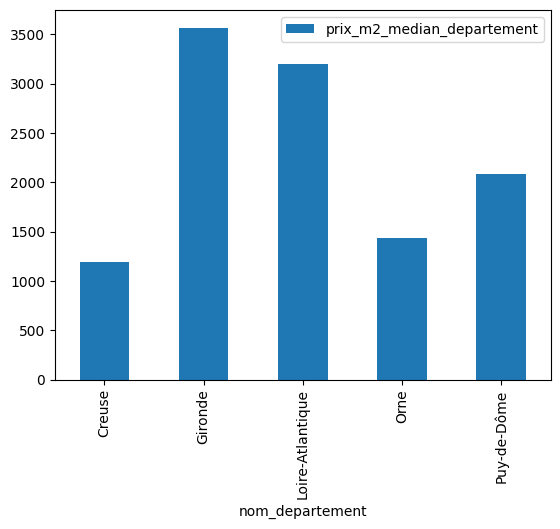

In [81]:
df[["nom_departement", "prix_m2_median_departement"]].drop_duplicates().set_index("nom_departement").plot(kind="bar")

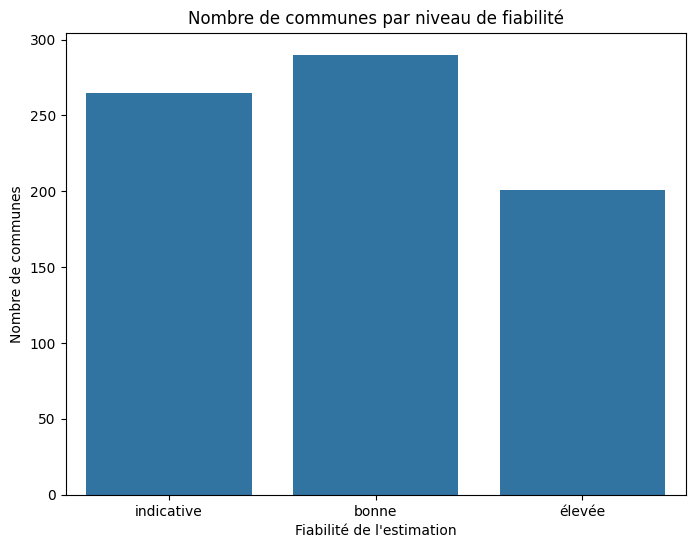

Le pourcentage de communes avec une fiabilité bonne est : 38.4 %
Le pourcentage de communes avec une fiabilité indicative est : 35.1 %
Le pourcentage de communes avec une fiabilité élevée est : 26.6 %


In [82]:
plt.figure(figsize=(8, 6))
sns.countplot(x=df["fiabilite"], order=["indicative", "bonne", "élevée"])
plt.title("Nombre de communes par niveau de fiabilité")
plt.xlabel("Fiabilité de l'estimation")
plt.ylabel("Nombre de communes")
plt.show()

# pourcentage de chaque catégorie
pourcentages = df["fiabilite"].value_counts(normalize=True) * 100
for categorie, pct in pourcentages.items():
    print(f"Le pourcentage de communes avec une fiabilité {categorie} est : {pct:.1f} %")

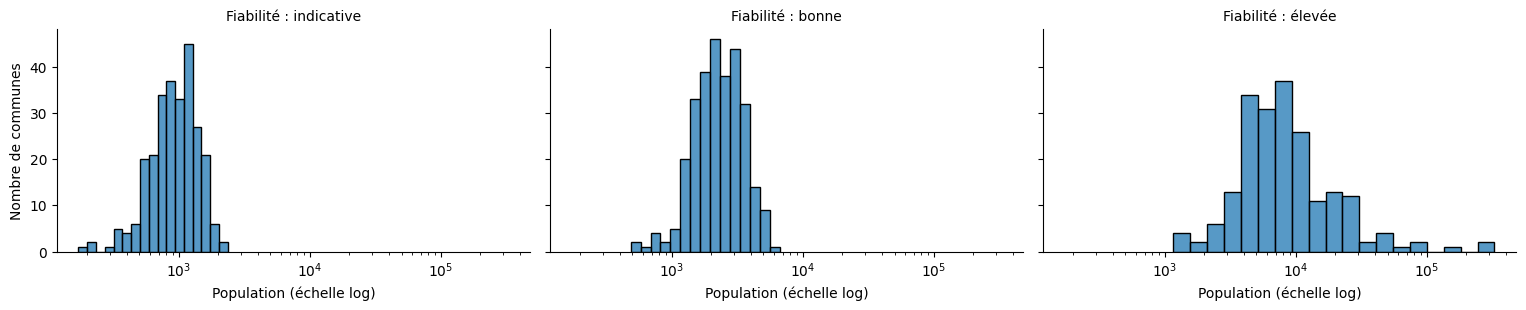

In [86]:
grid = sns.FacetGrid(df, col="fiabilite", col_order=["indicative", "bonne", "élevée"],
                     height=3.2, aspect=1.6)
grid.map(sns.histplot, "population", log_scale=True)
grid.set_titles("Fiabilité : {col_name}")
grid.set_axis_labels("Population (échelle log)", "Nombre de communes")